# STED Data 
This code will recreate figure panels as well as plot individual dendrites and determine summary values of key variables
>  mean diam <br>
>  length <br>

In [1]:
import sys
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

import os
import glob

plot_path="../output/plots"
mypath = plot_path


sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc
from plots import plot_dsc

from pathlib import Path

## Load dendritic diameter data
Set location of repo data (root folder) sets the paths for each dendrite analysed

In [ ]:
# Define root path and check existence
root = Path('../repo_data/')
if not root.exists():
    raise FileNotFoundError(f"Root folder '{root}' not found.")

# Define paths for different datasets
paths = {
    '3wk': {'path': root / 'STED/3week_thy1_dg/tables/'},
    '5wk': {'path': root / 'STED/5week_thy1_dg/tables/'},
    'prox': {'path': root / 'STED/dg_proximal/tables/'}
}

# Initialize STEDdata dictionary
STEDdata = {}

# Loop through each dataset
for dataset, d in paths.items():
    path_to_data = d['path']
    STEDdata[dataset] = {}
    
    # Get files matching the pattern in the dataset path
    for file in path_to_data.glob("*Local*"):
        print(file)  # Optional: print to confirm file paths
        name = file.name
        dendrite = 'dendrite' + name.split(' - ')[0]
        
        # Populate STEDdata with file details
        STEDdata[dataset][dendrite] = {
            'path': file,
            'file': name,
            'ex_factor': 1,
            'res': 0.04
        }

# Optionally, print or log STEDdata to verify paths and parameters
print(STEDdata)

F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\16 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\17 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\21 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\25 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\25-2 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\27 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\28 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\29 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\29-4 - Local Diameter.csv
F:\bonn\data\Distal_dendrite\morphology\repo_data\STED\3week_thy1_dg\tables\30 - Local Diameter.

Load and analyse each branch in the STED datasets

In [3]:
for n, dataSet in STEDdata.items():
    print(n)
    
    for name, dendrite in tqdm(dataSet.items()):
        #print(name)
        #print(data[name]['path'])
        
        file_path = dendrite['path']#+dendrite['file']
        dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

3wk


  0%|          | 0/29 [00:00<?, ?it/s]

100%|██████████| 29/29 [00:00<00:00, 38.05it/s]


5wk


100%|██████████| 21/21 [00:00<00:00, 46.30it/s]


prox


100%|██████████| 15/15 [00:00<00:00, 53.47it/s]


Manually adjust DSCs 
> add DSCs missing as diam increses slighlty in the middle <br>
> remove false postives

In [4]:
# Helper function to delete DSCs and update
def delete_DSCs_and_update(branch, indices):
    for idx in sorted(indices, reverse=True):  # Delete from end to avoid index shifting
        del branch['DSCs'][idx]
    update_DSCs(branch)
    update_compartments(branch)

# Helper function to update DSC properties
def update_DSC_properties(branch, prop_idx, mean_range, length_start, length_end):
    DSC = branch['DSCs'][prop_idx]
    branch['DSC_properties'][prop_idx]['mean'] = DSC.smth[mean_range[0]:mean_range[1]].mean()
    branch['DSC_properties'][prop_idx]['length'] = DSC.length[DSC.length.index[0] + length_end] - DSC.length[DSC.length.index[0] + length_start]

# Helper function to add a new DSC and update
def add_DSC_and_update(branch, data_range):
    DSC = branch['data'][data_range[0]:data_range[1]].copy()
    DSC.diam *= 1 / branch['ex_factor']
    DSC.smth *= 1 / branch['ex_factor']
    DSC.length *= branch['res'] / branch['ex_factor']
    DSC.pt_distance *= branch['res'] / branch['ex_factor']
    branch['DSCs'].append(DSC)
    update_DSCs(branch)
    update_compartments(branch)

# 3wks modifications
delete_DSCs_and_update(STEDdata['3wk']['dendrite25'], [0, 1])
delete_DSCs_and_update(STEDdata['3wk']['dendrite28'], [0, 1])
delete_DSCs_and_update(STEDdata['3wk']['dendrite29-4'], [0])
delete_DSCs_and_update(STEDdata['3wk']['dendrite39-21'], [2])

update_DSC_properties(STEDdata['3wk']['dendrite40-4'], 0, (37, 47), 37, 47)
delete_DSCs_and_update(STEDdata['3wk']['dendrite41-0'], [1])

# 5wks modifications
add_DSC_and_update(STEDdata['5wk']['dendrite36-2'], (145, 270))
update_DSC_properties(STEDdata['5wk']['dendrite38-1'], 0, (11, 32), 11, 32)
add_DSC_and_update(STEDdata['5wk']['dendrite42-2'], (50, 150))

delete_DSCs_and_update(STEDdata['5wk']['dendrite14'], [3])
delete_DSCs_and_update(STEDdata['5wk']['dendrite43-1'], [0])
delete_DSCs_and_update(STEDdata['5wk']['dendrite43-2'], [0])
delete_DSCs_and_update(STEDdata['5wk']['dendrite55'], [0])

### Create figure panels for Fig1 
Fig1D DSC mean diameter <br>
Fig1E DSC lenght

length mean = 1.9522497297297303 +- sem 0.21940289413890945 count 37


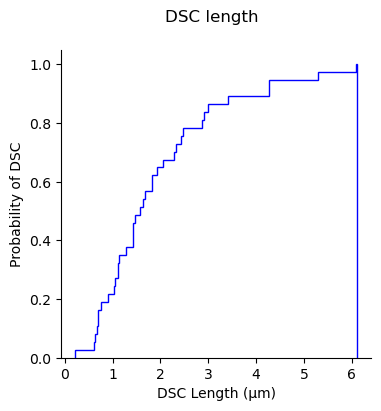

In [5]:
# Select property to plot [mean, lenght]
parameter='length'

df3= summary_dsc(STEDdata['3wk'], parameter)
df5= summary_dsc(STEDdata['5wk'], parameter)
dfProx= summary_dsc(STEDdata['prox'], parameter)
df = pd.concat([df3, df5])

fig, ax = plt.subplots(figsize=(4, 4))
n_bins=200
fig.suptitle('DSC '+parameter)

ax.set_xlabel("DSC Length (µm)" if parameter == 'length' else "DSC Diameter (nm)")
ax.set_ylabel("Probability of DSC")

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='blue', density=True, histtype='step', cumulative=True)
#ax.set_xlim([0,10])

fig.savefig(mypath+'/STED_DSC_'+parameter+'_Cumulative.svg', bbox_inches = 'tight')
print(f"{parameter} mean = {df.mean()} +- sem {df.sem()} count {df.count()}")

### Select dendrite and branch to analyse
Example dendrites shown in Fig. 1d 

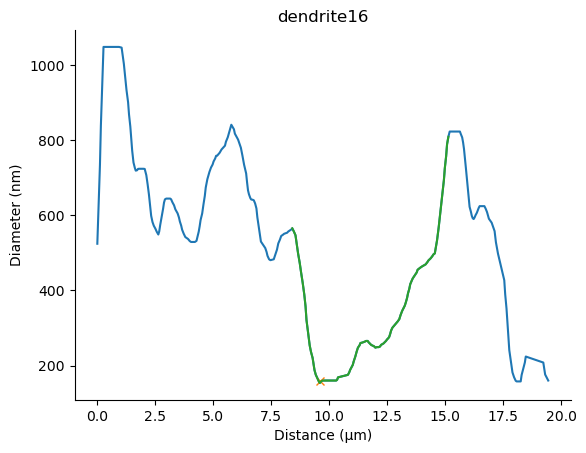

In [6]:
#data, dendrite branch
dend_name= 'dendrite16' 

fig, ax = plot_dsc(STEDdata['3wk'][dend_name],dend_name, corr=1)  

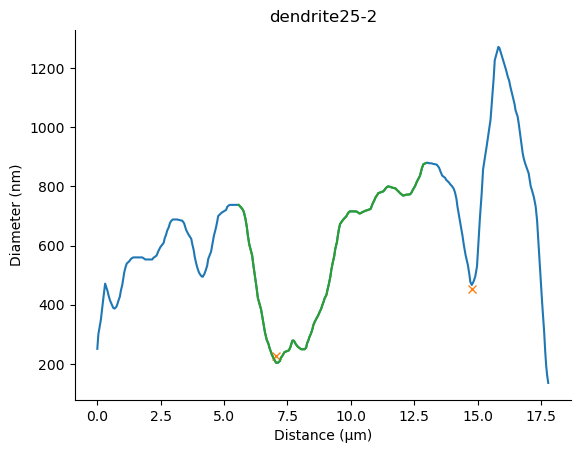

In [7]:
#data, dendrite branch
dend_name= 'dendrite25-2' 

fig, ax = plot_dsc(STEDdata['3wk'][dend_name],dend_name, corr=1)  